## Проект “Моделирование жидкосцинтилляционного детектора”
### Общая концепция
Рассмотрим сферический детектор радиусом $R$, заполненный сцинтиллирующей жидкостью.
В сцинтилляторе свет от взаимодействия частиц излучается изотропно, выход фотонов для события с энергией 1 МэВ равен $Y$.
Внутренняя поверхность детектора покрыта $N$ фотоумножителями, улавливающими свет от взаимодействия частиц.
Считаем, что у фотоумножителя плоский фотокатод радиусом $r$.
Bероятность выбивания хотя бы одного фотоэлектрона равна $a$.
Каждому фотоумножителю соответствует канал набора данных, сохраняющий число фотоэлектронов.

### Задание 2

Создать класс Source со следующими параметрами:
              Y = 10000 фотонов/МэВ

Разработать метод, разыгрывающий начальные направления фотонов для события с энергией E. При описании излучения света использовать следующие допущения:
- свет излучается изотропно
- выход фотонов линеен по энергии с коэффициентом пропорциональности Y 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import source
import coordinates

# Y = 10000 фотонов/МэВ; seed фиксирует ГСЧ, чтобы результаты ноутбука воспроизводились
src = source.Source(seed=42)
print(src)
print(f'Световыход Y = {src.Y:.0f} фотонов/МэВ')

Source(Y=10000 фотонов/МэВ)
Световыход Y = 10000 фотонов/МэВ


In [2]:
# Метод разыгрывает начальные направления фотонов для события с энергией E.
# Число фотонов линейно по энергии: N = Y·E
for E in (0.0, 0.5, 1.0, 2.0):
    directions = src.generate_directions(E)
    assert directions.shape == (src.photon_number(E), 3)
    assert len(directions) == int(src.Y * E)
    print(f'E = {E:>4.1f} МэВ  →  N = {len(directions):>6} фотонов,  массив {directions.shape}')

E =  0.0 МэВ  →  N =      0 фотонов,  массив (0, 3)
E =  0.5 МэВ  →  N =   5000 фотонов,  массив (5000, 3)
E =  1.0 МэВ  →  N =  10000 фотонов,  массив (10000, 3)
E =  2.0 МэВ  →  N =  20000 фотонов,  массив (20000, 3)


In [3]:
# Проверка: направления единичные и изотропные (фиксированный seed для воспроизводимости)
check = source.Source(seed=2024)
v = check.generate_directions(1.0)
assert np.allclose(np.linalg.norm(v, axis=1), 1.0)      # все |v| = 1
r, theta, phi = coordinates.cartesian_to_spherical(v)
assert np.allclose(r, 1.0)

cos_theta = np.cos(theta)
print('Средний вектор направлений:', np.round(v.mean(axis=0), 4),
      '|mean| =', round(float(np.linalg.norm(v.mean(axis=0))), 4), '(ожидается ~0)')
print(f'cos(theta): среднее {cos_theta.mean():+.4f} (0), '
      f'ст. откл. {cos_theta.std():.4f} (1/sqrt(3) = {1/np.sqrt(3):.4f})')
print(f'phi: среднее {phi.mean():.4f} (pi = {np.pi:.4f}), '
      f'ст. откл. {phi.std():.4f} (pi/sqrt(3) = {np.pi/np.sqrt(3):.4f})')

# Равномерность по площади сферы: в равных интервалах cos(theta) должно быть ~N/10 фотонов
counts, _ = np.histogram(cos_theta, bins=10, range=(-1.0, 1.0))
expected = len(v) / 10
print('Число фотонов в 10 равных интервалах cos(theta):', counts.tolist())
print(f'Ожидание {expected:.0f} в каждом; макс. отклонение {np.abs(counts - expected).max():.0f} '
      f'(5σ ≈ {5*np.sqrt(expected):.0f})')
assert np.abs(counts - expected).max() < 5 * np.sqrt(expected)

Средний вектор направлений: [-0.0074  0.0006  0.0017] |mean| = 0.0076 (ожидается ~0)
cos(theta): среднее +0.0017 (0), ст. откл. 0.5782 (1/sqrt(3) = 0.5774)
phi: среднее 3.1403 (pi = 3.1416), ст. откл. 1.8003 (pi/sqrt(3) = 1.8138)
Число фотонов в 10 равных интервалах cos(theta): [984, 1028, 997, 954, 995, 1008, 1027, 983, 1000, 1024]
Ожидание 1000 в каждом; макс. отклонение 46 (5σ ≈ 158)


In [4]:
# Воспроизводимость (один seed), сферические углы и обработка некорректных параметров
a = source.Source(seed=7).generate_directions(0.01)
b = source.Source(seed=7).generate_directions(0.01)
assert np.array_equal(a, b)
print('Одинаковый seed → одинаковые направления:', np.array_equal(a, b))

theta, phi = src.generate_angles(0.01)
print(f'Сферические углы: theta в [{theta.min():.3f}, {theta.max():.3f}] рад, '
      f'phi в [{phi.min():.3f}, {phi.max():.3f}] рад')

for bad_E in (-1.0, float('nan'), float('inf')):
    try:
        src.generate_directions(bad_E)
    except ValueError as exc:
        print(f'E = {bad_E}: ValueError — {exc}')
try:
    source.Source(Y=0)
except ValueError as exc:
    print(f'Y = 0: ValueError — {exc}')

Одинаковый seed → одинаковые направления: True
Сферические углы: theta в [0.277, 2.884] рад, phi в [0.041, 6.168] рад
E = -1.0: ValueError — Энергия E должна быть конечным неотрицательным числом, МэВ
E = nan: ValueError — Энергия E должна быть конечным неотрицательным числом, МэВ
E = inf: ValueError — Энергия E должна быть конечным неотрицательным числом, МэВ
Y = 0: ValueError — Световыход Y должен быть конечным положительным числом


### Результат

- Класс `Source` (модуль `source.py`) имеет параметр `Y = 10000 фотонов/МэВ`.
- Метод `generate_directions(E)` возвращает массив формы `(N, 3)` единичных векторов — начальные направления фотонов; число фотонов `N = Y·E` (линейный выход по энергии).
- Изотропность обеспечена равномерным розыгрышем `cos(theta)` на `[-1, 1]` и `phi` на `[0, 2π)`; проверки выше подтверждают нулевое среднее направление и равномерность по телесному углу.
- Дополнительно: `generate_angles(E)` возвращает пару `(theta, phi)`, `photon_number(E)` — число фотонов, параметр `seed` обеспечивает воспроизводимость событий.

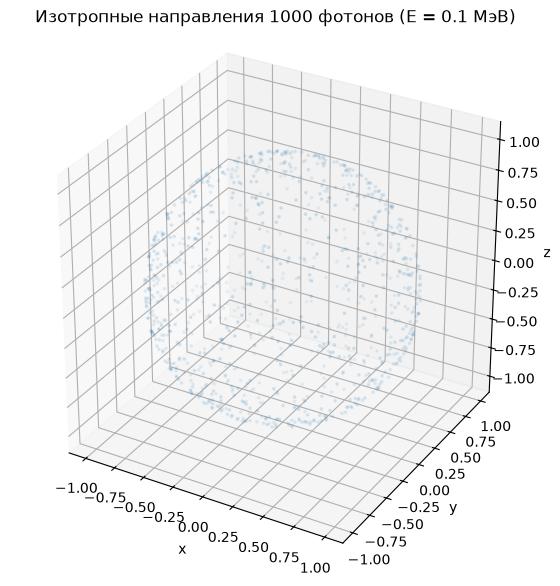

In [5]:
# Визуализация: направления 1000 фотонов на единичной сфере
%matplotlib inline
from mpl_toolkits.mplot3d import Axes3D  # регистрирует проекцию '3d'

v_plot = source.Source(seed=1).generate_directions(0.1)
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(v_plot[:, 0], v_plot[:, 1], v_plot[:, 2], s=3, alpha=0.35)
ax.set_box_aspect([1, 1, 1])
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
ax.set_title(f'Изотропные направления {len(v_plot)} фотонов (E = 0.1 МэВ)')
plt.tight_layout()
plt.show()